# regression model - california housing prices (proof of concept)

This regression model is a variant of the base model, adapted for numerical tabular data vs TF-IDF, vectors, vector embeddings, and text data for mathematical LLM inference which may be a fairly new concept. It demonstrates the versatility of version-tab by applying machine learning to predict median housing prices with real estate data.

In [1]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

2025-08-06 00:54:18.189027: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: SSE4.1 SSE4.2 AVX AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [2]:
# Set seeds
np.random.seed(578)
tf.random.set_seed(578)

# Load California Housing dataset
data = fetch_california_housing()
X, y = data.data, data.target

print("Feature names:", data.feature_names)
print("Input shape:", X.shape)
print("Target shape:", y.shape)

Feature names: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']
Input shape: (20640, 8)
Target shape: (20640,)


In [3]:
# Load the data as a pandas DataFrame
data = fetch_california_housing(as_frame=True)

# Combine features and target into a single DataFrame
df = data.frame

# Print the first few rows
df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [4]:
# Train-test split and standardization
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=578)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [5]:
from sklearn.model_selection import train_test_split

X_train_final, X_val, y_train_final, y_val = train_test_split(
    X_train, y_train, test_size=0.1, random_state=42
)

In [6]:
print(X_train.shape)

(16512, 8)


In [7]:
print(X_test.shape)

(4128, 8)


In [10]:
from sklearn.metrics import r2_score
from tensorflow.keras.callbacks import Callback

class R2Logger(Callback):
    def __init__(self, X_train, y_train, X_val, y_val):
        self.X_train = X_train
        self.y_train = y_train
        self.X_val = X_val
        self.y_val = y_val
        self.train_r2_scores = []
        self.val_r2_scores = []

    def on_epoch_end(self, epoch, logs=None):
        y_train_pred = self.model.predict(self.X_train, verbose=0).flatten()
        y_val_pred = self.model.predict(self.X_val, verbose=0).flatten()
        train_r2 = r2_score(self.y_train, y_train_pred)
        val_r2 = r2_score(self.y_val, y_val_pred)
        self.train_r2_scores.append(train_r2)
        self.val_r2_scores.append(val_r2)
        print(f" Epoch {epoch+1}: train R² = {train_r2:.4f} - val R² = {val_r2:.4f}")

In [11]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout

# Build regression model
regressionmodel = Sequential([
    Input(shape=(X_train.shape[1],)),
    Dense(128, activation='relu'),
    Dropout(0.3),
    Dense(64, activation='relu'),
    Dropout(0.2),
    Dense(1)
])

regressionmodel.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)

r2_logger = R2Logger(X_train_final, y_train_final, X_val, y_val)

# Train
history = regressionmodel.fit(
    X_train_final, y_train_final,
    epochs=30,
    batch_size=32,
    validation_data=(X_val, y_val),
    callbacks=[r2_logger],
    verbose=1
)


# Model evaulation metrics
loss, mae = regressionmodel.evaluate(X_test, y_test, verbose=0)
y_pred = regressionmodel.predict(X_test).flatten()
r2 = r2_score(y_test, y_pred)

print(f"\nR² Score: {r2:.4f}")
print(f"Test MSE (Loss): {loss:.4f}")
print(f"Test MAE: {mae:.4f}")

Epoch 1/30
452/465 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1.6346 - mae: 0.8394 Epoch 1: train R² = 0.6692 - val R² = 0.6723
465/465 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - loss: 1.6152 - mae: 0.8342 - val_loss: 0.4311 - val_mae: 0.4606
Epoch 2/30
441/465 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.6195 - mae: 0.5399 Epoch 2: train R² = 0.7068 - val R² = 0.7034
465/465 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.6164 - mae: 0.5391 - val_loss: 0.3902 - val_mae: 0.4357
Epoch 3/30
461/465 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.4888 - mae: 0.4957 Epoch 3: train R² = 0.7186 - val R² = 0.7155
465/465 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.4887 - mae: 0.4956 - val_loss: 0.3744 - val_mae: 0.4243
Epoch 4/30
454/465 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.4984 - mae: 0.4876 Epoch 4: train R² = 0.7257 - val R² = 0.7175
465/465 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.4978 - mae: 0.4875 - val_loss: 0.3716 - val_mae: 0.4326
Epoch 5/30
446/465 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.4463 -

129/129 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step  


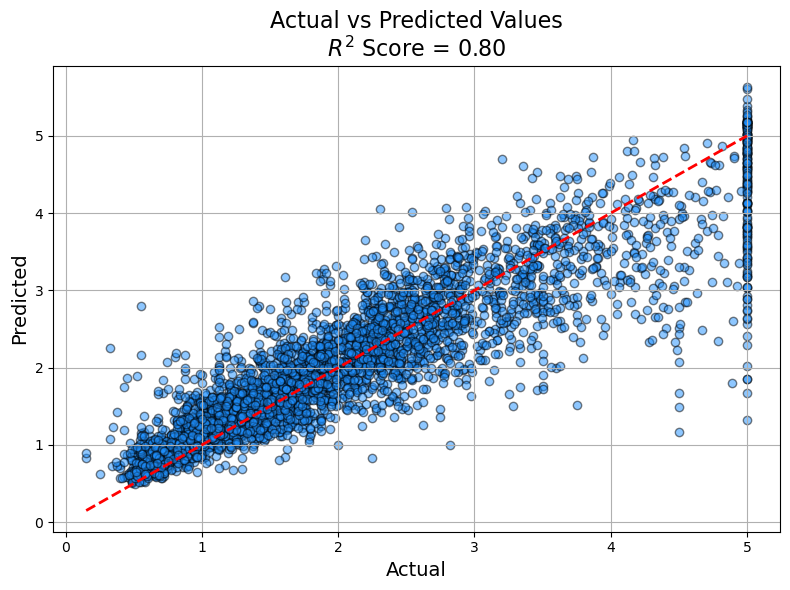

In [12]:
from sklearn.metrics import r2_score
import matplotlib.pyplot as plt

y_pred = regressionmodel.predict(X_test).flatten() 
r2 = r2_score(y_test, y_pred)                      

plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.5, color='dodgerblue', edgecolor='k')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.title(f"Actual vs Predicted Values\n$R^2$ Score = {r2:.2f}", fontsize=16)
plt.xlabel("Actual", fontsize=14)
plt.ylabel("Predicted", fontsize=14)
plt.grid(True)
plt.tight_layout()
plt.show()

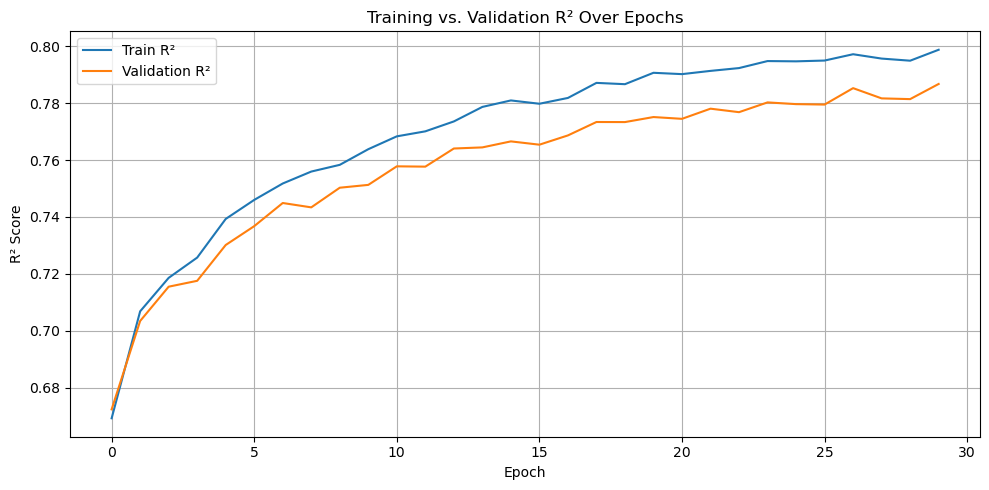

In [13]:
plt.figure(figsize=(10, 5))
plt.plot(r2_logger.train_r2_scores, label='Train R²', color='#1f77b4')     
plt.plot(r2_logger.val_r2_scores, label='Validation R²', color='#ff7f0e')  
plt.xlabel("Epoch")
plt.ylabel("R² Score")
plt.title("Training vs. Validation R² Over Epochs")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

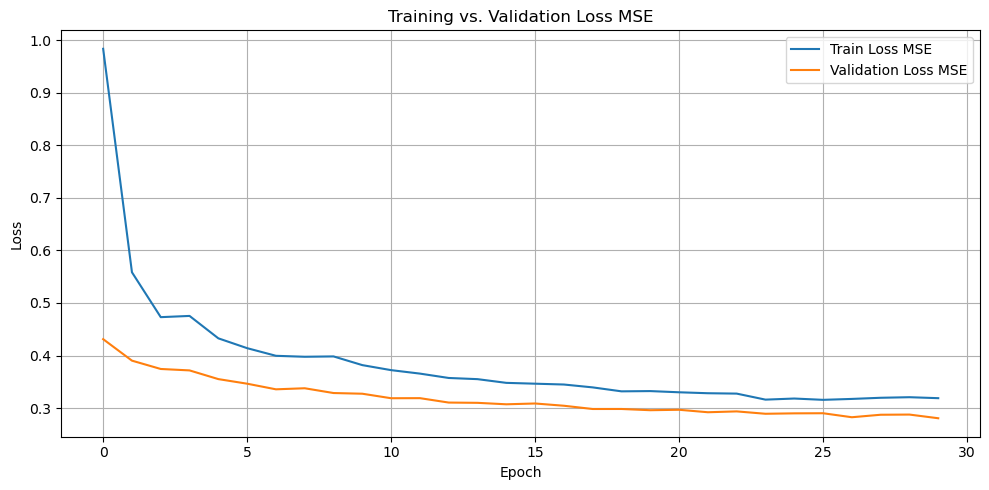

In [14]:
plt.figure(figsize=(10, 5))
plt.plot(history.history['loss'], label='Train Loss MSE')
plt.plot(history.history['val_loss'], label='Validation Loss MSE')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training vs. Validation Loss MSE')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

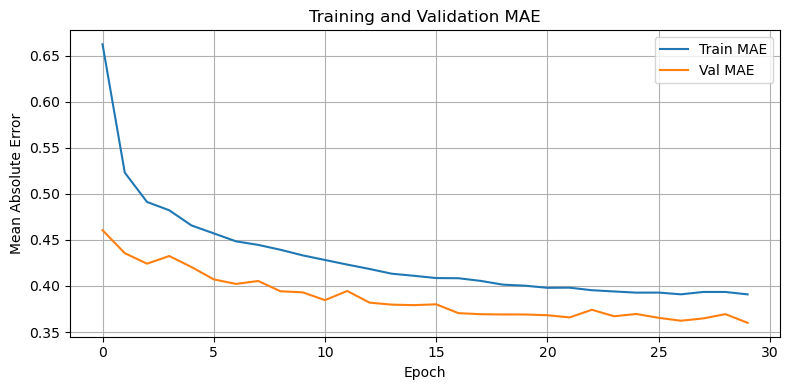

In [15]:
plt.figure(figsize=(8, 4))
plt.plot(history.history['mae'], label='Train MAE')
plt.plot(history.history['val_mae'], label='Val MAE')
plt.title("Training and Validation MAE")
plt.xlabel("Epoch")
plt.ylabel("Mean Absolute Error")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [16]:
regressionmodel.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 128)            │         1,152 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 28,421 (111.02 KB)

 Trainable params: 9,473 (37.00 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 18,948 (74.02 KB)

In [ ]:
# Save model summary (optional)
with open("model_summary_regression.txt", "w") as f:
    regressionmodel.summary(print_fn=lambda line: f.write(line + "\n"))

print("Model summary saved to model_summary_regression.txt")

In [ ]:
# end of demo with lr model version for tabular data with version-tab